Equazione della parabola : y = 0.118x^2 + -3.013x + 18.668

Valori previsti dal modello:
x = 0.0 -> y = 18.67
x = 1.0 -> y = 15.77
x = 2.0 -> y = 13.11
x = 3.0 -> y = 10.69
x = 4.0 -> y = 8.51
x = 5.0 -> y = 6.56
x = 6.0 -> y = 4.84
x = 7.0 -> y = 3.36
x = 8.0 -> y = 2.12
x = 9.0 -> y = 1.12
x = 10.0 -> y = 0.35
x = 11.0 -> y = -0.18
x = 12.0 -> y = -0.48
x = 13.0 -> y = -0.54
x = 14.0 -> y = -0.36
x = 15.0 -> y = 0.05
x = 16.0 -> y = 0.70
x = 17.0 -> y = 1.58
x = 18.0 -> y = 2.70
x = 19.0 -> y = 4.06
x = 20.0 -> y = 5.65





Valore simulato valido: x = 0.00, y = 19.07
Valore simulato valido: x = 1.00, y = 15.59
Valore simulato valido: x = 2.00, y = 12.82
Valore simulato valido: x = 3.00, y = 10.47
Valore simulato valido: x = 4.00, y = 8.46
Valore simulato valido: x = 5.00, y = 6.59
Valore simulato valido: x = 6.00, y = 4.97
Valore simulato valido: x = 7.00, y = 3.58
Valore simulato valido: x = 8.00, y = 2.34
Valore simulato valido: x = 9.00, y = 1.15
Valore simulato valido: x = 10.00

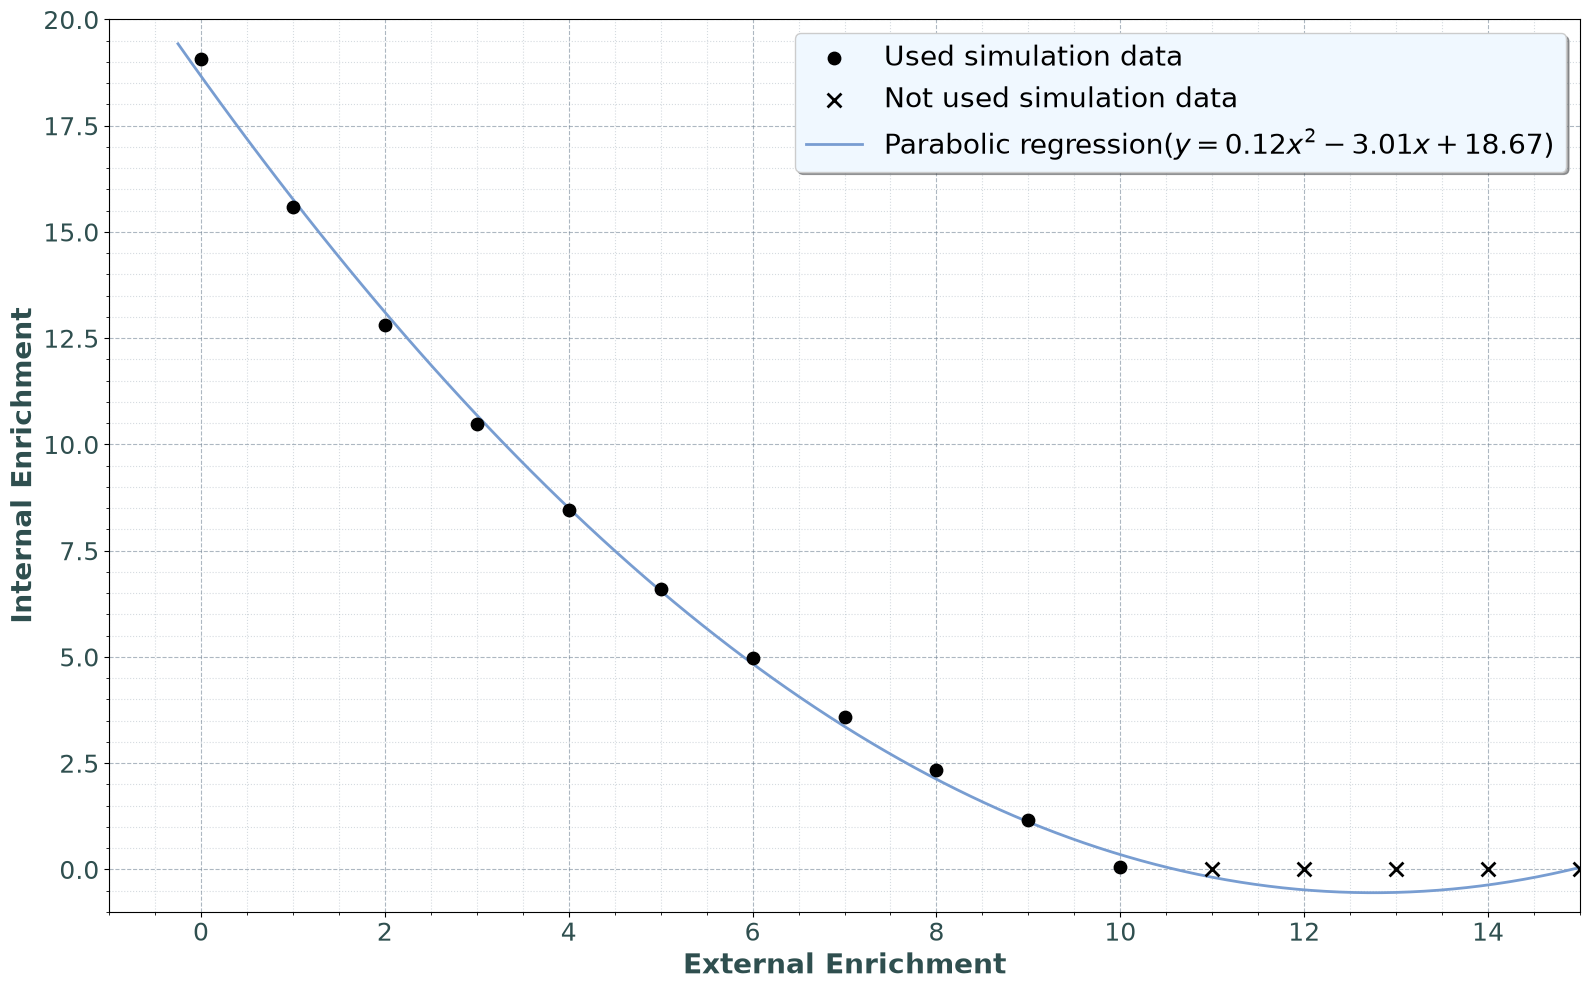

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def analizza_e_plotta(file_path):
    """
    Legge i dati di simulazione, esegue regressione parabolica ESCLUDENDO i punti con y=0,
    e genera il plot differenziando i marcatori per y=0.
    """
    # Definizione manuale delle colonne
    nomi_colonne = [
        'Pres', 'moltiplicatore', 'PERC_water', 'Arricch_MAX',
        'Arricch_min', 'T_WATER', 'T_FUEL', 'K_max', 'std_k_max',
        'K_auto', 'std_k_auto', 'Compatibilità'
    ]

    # Lettura del file
    df = pd.read_csv(file_path, sep=r'\s+', skiprows=3, names=nomi_colonne, engine='python')

    # Estrazione array completi per la visualizzazione
    x_tutti = df['Arricch_min'].values
    y_tutti = df['Arricch_MAX'].values

    # --- MODIFICA 1: Filtro dei dati per la regressione ---
    # Creiamo maschere booleane per separare i dati validi (y > 0) da quelli nulli (y = 0)
    maschera_validi = y_tutti > 0
    maschera_zeri = y_tutti == 0
    x_validi = x_tutti[maschera_validi]
    y_validi = y_tutti[maschera_validi]
    x_zeri = x_tutti[maschera_zeri]
    y_zeri = y_tutti[maschera_zeri]
    # --- MODIFICA 2: Regressione solo sui dati validi ---
    # Calcolo regressione parabolica (polinomio di grado 2) usando SOLO x_validi, y_validi
    a, b, c = np.polyfit(x_validi, y_validi, 2)
    # Vettori per l'estrapolazione del modello (x da 1 a 20)
    x_pred = np.arange(0, 21)
    y_pred = a * x_pred**2 + b * x_pred + c
    # Output analitico a terminale (ora basato sul nuovo modello)
    print(f"Equazione della parabola : y = {a:.3f}x^2 + {b:.3f}x + {c:.3f}\n")
    print("Valori previsti dal modello:")
    for x, y in zip(x_pred, y_pred):
        y_visualizzato = y
        print(f"x = {x:2.1f} -> y = {y_visualizzato:.2f}")
    print("\n\n\n\n")

    for x, y in zip(x_validi, y_validi):
        print(f"Valore simulato valido: x = {x:.2f}, y = {y:.2f}")
    # Configurazione della Figura
    fig, ax = plt.subplots(figsize=(16, 10))
    # --- MODIFICA 3: Plot differenziato dei dati di simulazione ---
    # 3a. Plot dei dati validi (pallini neri)
    ax.scatter(x_validi, y_validi, color='#000000', s=80, zorder=5, label='Used simulation data')

    # 3b. Plot dei dati con y=0 (X nera)
    ax.scatter(x_zeri, y_zeri, color='#000000', marker='x', s=100, linewidth=2, zorder=5, label='Not used simulation data ')
    # Plot della curva di regressione
    x_full = np.linspace(-0.25, 15, 100) # Usiamo più punti per una curva morbida
    y_full = a * x_full**2 + b * x_full + c
    ax.plot(x_full, y_full, color='#789DD1', linestyle='-', linewidth=2, zorder=4, label=f'Parabolic regression($y={a:.2f}x^2{b:.2f}x+{c:.2f}$)')
    # --- MODIFICA 4: Plot differenziato dei valori estrapolati ---
    # Maschere per i valori previsti
    maschera_pred_validi = y_pred > 0
    maschera_pred_zeri = y_pred <= 0 # Consideriamo zeri anche i valori leggermente negativi del modello
    # Formattazione Titolo e Assi
    ax.set_xlabel('External Enrichment', fontsize=20, fontweight='bold', color='#2F4F4F')
    ax.set_ylabel('Internal Enrichment', fontsize=20, fontweight='bold', color='#2F4F4F')
    # Limiti assi per coerenza
    ax.set_xlim(-1, 15)
    ax.set_ylim(-1, 20)
    # Formattazione Tick uniformata (Major: 14, Minor: 12)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)
    offset = 0.05 # 50 PCM
    y_upper = y_full + offset
    y_lower = y_full - offset
    # Setup della griglia avanzata uniformata
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')

    # Setup Legenda uniformata (loc='best', fontsize=16)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')
    plt.tight_layout()
    #plt.savefig('regressione_parabolica_filtrata.png', dpi=300)
    plt.show()
    return a, b, c

a, b, c = analizza_e_plotta('../result_final.txt')



Equazione della parabola (sul vero anello): y = 0.098x^2 + -2.344x + 15.556

Valori previsti dal modello:
x = 0.0 -> y = 15.56
x = 1.0 -> y = 13.31
x = 2.0 -> y = 11.26
x = 3.0 -> y = 9.41
x = 4.0 -> y = 7.75
x = 5.0 -> y = 6.30
x = 6.0 -> y = 5.03
x = 7.0 -> y = 3.97
x = 8.0 -> y = 3.10
x = 9.0 -> y = 2.43
x = 10.0 -> y = 1.96
x = 11.0 -> y = 1.68
x = 12.0 -> y = 1.60
x = 13.0 -> y = 1.72
x = 14.0 -> y = 2.03
x = 15.0 -> y = 2.54
x = 16.0 -> y = 3.25
x = 17.0 -> y = 4.15
x = 18.0 -> y = 5.25
x = 19.0 -> y = 6.55
x = 20.0 -> y = 8.04



Valore simulato valido: x = 0.00, y = 15.89
Valore simulato valido: x = 1.00, y = 13.16
Valore simulato valido: x = 2.00, y = 11.01
Valore simulato valido: x = 3.00, y = 9.23
Valore simulato valido: x = 4.00, y = 7.71
Valore simulato valido: x = 5.00, y = 6.33
Valore simulato valido: x = 6.00, y = 5.14
Valore simulato valido: x = 7.00, y = 4.15
Valore simulato valido: x = 8.00, y = 3.28
Valore simulato valido: x = 9.00, y = 2.46
Valore simulato valido: 

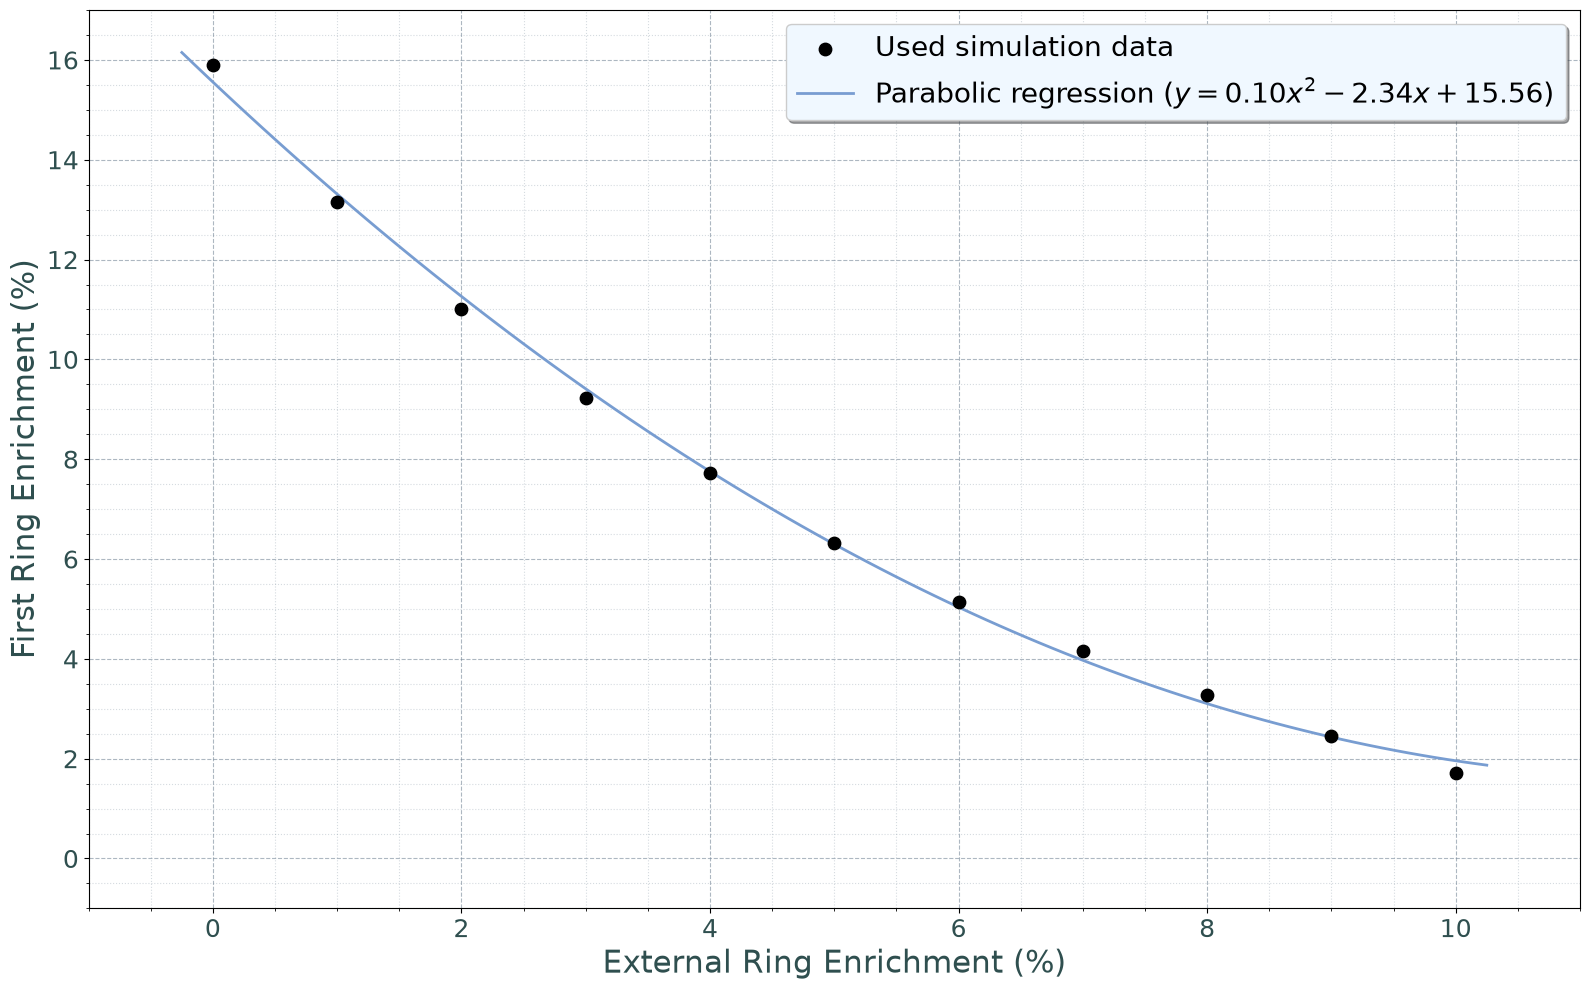

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def analizza_e_plotta(file_path):
    """
    Legge i dati di simulazione, esegue regressione parabolica ESCLUDENDO i punti con y=0,
    e genera il plot sul VERO arricchimento del primo anello fisico.
    """
    # Definizione manuale delle colonne
    nomi_colonne = [
        'Pres', 'moltiplicatore', 'PERC_water', 'Arricch_MAX',
        'Arricch_min', 'T_WATER', 'T_FUEL', 'K_max', 'std_k_max',
        'K_auto', 'std_k_auto', 'Compatibilità'
    ]
    
    # Lettura del file
    df = pd.read_csv(file_path, sep=r'\s+', skiprows=3, names=nomi_colonne, engine='python')
    
    # Estrazione array completi
    x_tutti = df['Arricch_min'].values
    a_M_tutti = df['Arricch_MAX'].values  # Questo è il valore nominale (i=0)
    
    # --- MODIFICA 1: Calcolo VERO arricchimento del primo anello fisico (i=2) ---
    # Formula originale OpenMC: e_i = a_M - (a_M - a_m) * (i / (num_rings - 1))
    y_tutti = np.zeros_like(a_M_tutti)
    for idx in range(len(a_M_tutti)):
        if a_M_tutti[idx] > 0:
            # Calcolo per i=2 e num_rings-1 = 12
            y_tutti[idx] = a_M_tutti[idx] - (a_M_tutti[idx] - x_tutti[idx]) * (2.0 / 12.0)
        else:
            y_tutti[idx] = 0.0

    # Creiamo maschere booleane per separare i dati validi da quelli nulli
    maschera_validi = y_tutti > 0
    maschera_zeri = y_tutti == 0

    x_validi = x_tutti[maschera_validi]
    y_validi = y_tutti[maschera_validi]

    x_zeri = x_tutti[maschera_zeri]
    y_zeri = y_tutti[maschera_zeri]

    # --- MODIFICA 2: Regressione solo sui dati validi ---
    a, b, c = np.polyfit(x_validi, y_validi, 2)

    # Vettori per l'estrapolazione del modello (x da 1 a 20)
    x_pred = np.arange(0, 21)
    y_pred = a * x_pred**2 + b * x_pred + c

    # Output analitico a terminale
    print(f"Equazione della parabola (sul vero anello): y = {a:.3f}x^2 + {b:.3f}x + {c:.3f}\n")
    print("Valori previsti dal modello:")
    for x, y in zip(x_pred, y_pred):
        print(f"x = {x:2.1f} -> y = {y:.2f}")

    print("\n\n")
    
    for x, y in zip(x_validi, y_validi):
        print(f"Valore simulato valido: x = {x:.2f}, y = {y:.2f}")

   # Configurazione della Figura
    fig, ax = plt.subplots(figsize=(16, 10))

    # --- MODIFICA 3: Plot differenziato dei dati di simulazione ---
    ax.scatter(x_validi, y_validi, color='#000000', s=80, zorder=5, label='Used simulation data')
    #ax.scatter(x_zeri, y_zeri, color='#000000', marker='x', s=100, linewidth=2, zorder=5, label='Not used simulation data')

    # Plot della curva di regressione
    x_full = np.linspace(-0.25, 10.25, 100) 
    y_full = a * x_full**2 + b * x_full + c
    
    # Formattazione equazione nel label per gestire bene i segni
    segno_b = "+" if b >= 0 else ""
    segno_c = "+" if c >= 0 else ""
    label_eq = f'Parabolic regression ($y={a:.2f}x^2 {segno_b}{b:.2f}x {segno_c}{c:.2f}$)'
    ax.plot(x_full, y_full, color='#789DD1', linestyle='-', linewidth=2, zorder=4, label=label_eq)

    # Formattazione Assi (Font 22, nessun grassetto)
    ax.set_xlabel('External Ring Enrichment (%)', fontsize=22, color='#2F4F4F')
    ax.set_ylabel('First Ring Enrichment (%)', fontsize=22, color='#2F4F4F')

    ax.set_xlim(-1, 11)
    ax.set_ylim(-1, 17)

    # Formattazione Tick
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)

    # Setup della griglia
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Setup Legenda (loc='best', fontsize=20)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')

    plt.tight_layout()
    plt.savefig('regressione_parabolica_filtrata.png', dpi=300)
    plt.show()

    return a, b, c

a, b, c = analizza_e_plotta('../result_final.txt')

### --- Analisi Rette --- ###

Retta 0 [Teorica: P(0, 19.07) -> P(11, 0.00)]: Media = 9.537
Retta 1 [Teorica: P(0, 15.59) -> P(11, 1.00)]: Media = 8.296
Retta 2 [Teorica: P(0, 12.82) -> P(11, 2.00)]: Media = 7.408
Retta 3 [Teorica: P(0, 10.47) -> P(11, 3.00)]: Media = 6.735
Retta 4 [Teorica: P(0, 8.46) -> P(11, 4.00)]: Media = 6.229
Retta 5 [Teorica: P(0, 6.59) -> P(11, 5.00)]: Media = 5.796
Retta 6 [Teorica: P(0, 4.97) -> P(11, 6.00)]: Media = 5.483
Retta 7 [Teorica: P(0, 3.58) -> P(11, 7.00)]: Media = 5.290
Retta 8 [Teorica: P(0, 2.34) -> P(11, 8.00)]: Media = 5.170
Retta 9 [Teorica: P(0, 1.15) -> P(11, 9.00)]: Media = 5.076
Retta 10 [Teorica: P(0, 0.07) -> P(11, 10.00)]: Media = 5.032


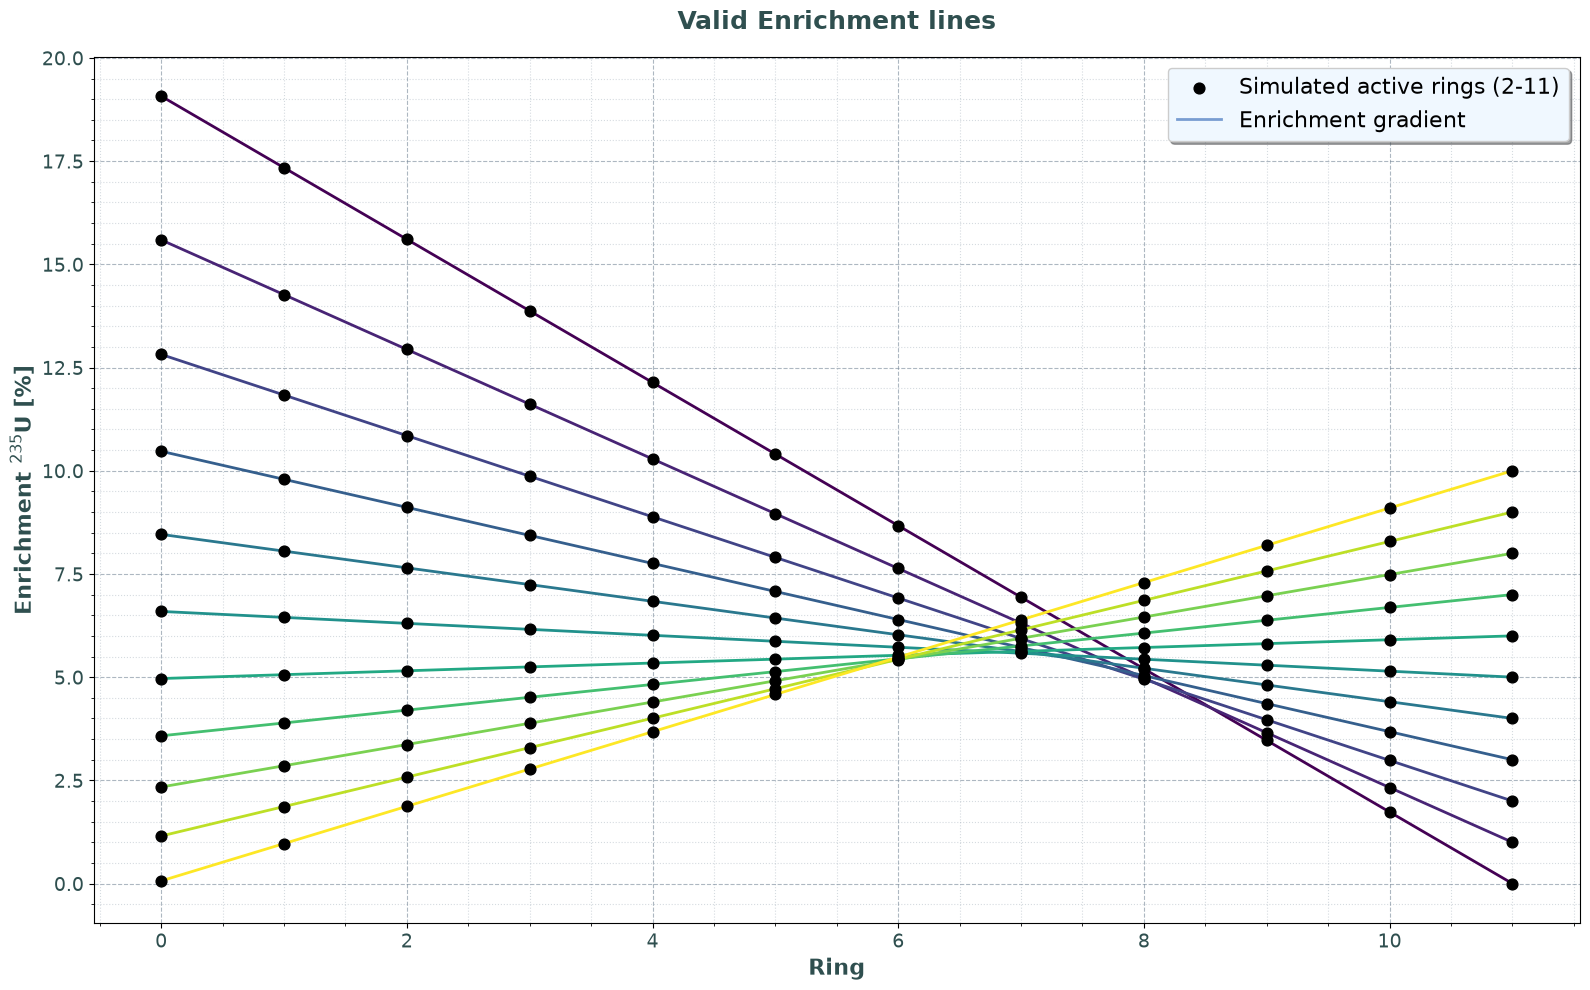

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def plot_rette_filtrate(x_pred, y_pred, num_rings=12, n_rings_removed=2):
    """
    Traccia il profilo di arricchimento radiale basato sulla geometria fisica.
    x_pred: array degli arricchimenti esterni all'ultimo anello (a_ext)
    y_pred: array degli arricchimenti interni teorici all'anello 0 (a_int)
    num_rings: numero totale di anelli calcolati (incluso lo 0 centrale)
    n_rings_removed: numero di anelli rimossi per fare spazio alla pipe
    """
    print("### --- Analisi Rette --- ###\n")
    
    fig, ax = plt.subplots(figsize=(16, 10))
    media_vect = []
    
    # Array degli anelli fisicamente presenti nel nocciolo (es. da 1 a 11)
    x_discrete = np.arange(n_rings_removed, num_rings)
    
    # Colormap per le rette valide
    colors = cm.viridis(np.linspace(0, 1, len(x_pred)))
    
    for i, (a_ext, a_int) in enumerate(zip(x_pred, y_pred)):
        
        # FILTRO: Se l'arricchimento all'anello 0 (teorico) è 0, salta
        if a_int <= 0:
            continue
            
        # Calcolo coefficienti retta teorica: y = m*x + q
        # Il gradiente parte esattamente da x=0 fino all'ultimo anello (num_rings - 1)
        m = (a_ext - a_int) / (num_rings - 1)
        q = a_int
        
        # Valutazione della retta SOLO sui pin discreti reali/attivi
        y_discrete = m * x_discrete + q
        media_y = np.mean(y_discrete)
        
        print(f"Retta {i} [Teorica: P(0, {a_int:.2f}) -> P({num_rings-1}, {a_ext:.2f})]: Media = {media_y:.3f}")
        media_vect.append(media_y)
        
        # Plot della retta e dei punti campionati
        ax.plot(x_discrete, y_discrete, color=colors[i], linestyle='-', linewidth=2, zorder=4)
        ax.scatter(x_discrete, y_discrete, color='#000000', s=60, zorder=5)

    # Formattazione grafica standard
    ax.set_title('Valid Enrichment lines', fontsize=18, fontweight='bold', color='#2F4F4F', pad=20)
    ax.set_xlabel('Ring', fontsize=16, fontweight='bold', color='#2F4F4F')
    ax.set_ylabel('Enrichment $^{235}$U [%]', fontsize=16, fontweight='bold', color='#2F4F4F')
    
    # Formattazione Tick (Major: 14, Minor: 12)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=14, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)
    
    # Griglia avanzata
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Legenda customizzata (loc='best', fontsize=16)
    ax.scatter([], [], color='#000000', s=60, label=f'Simulated active rings ({n_rings_removed+2}-{num_rings-1})')
    ax.plot([], [], color='#789DD1', linestyle='-', linewidth=2, label='Enrichment gradient')
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=16, facecolor='#F0F8FF')

    plt.tight_layout()
    #plt.savefig('retta_arricchimento.png', dpi=300)
    plt.show()
    
    return np.array(media_vect)

# Esempio di applicazione (da sostituire con i tuoi polinomi/valori reali)
x_pred = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

y_pred = np.array([19.073 , 15.591 , 12.817 , 10.471, 8.458 ,6.592 ,4.966 , 3.579 , 2.339 , 1.152, 0.065])

res = plot_rette_filtrate(x_pred, y_pred, num_rings=12, n_rings_removed=0)

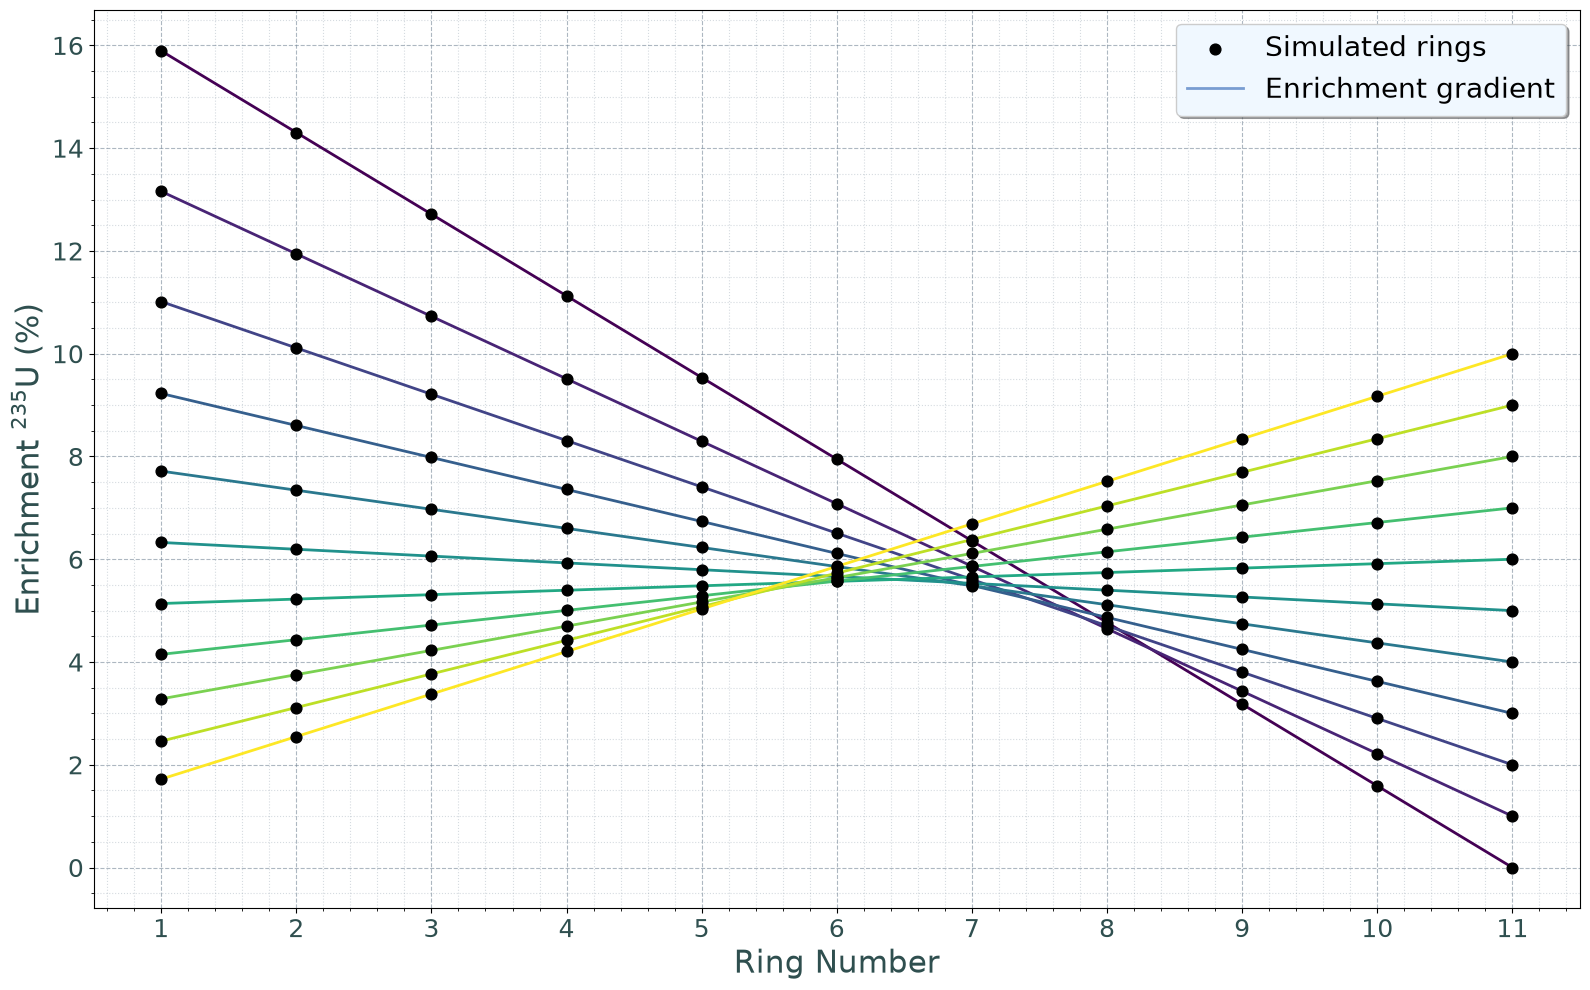

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def plot_rette_filtrate(x_pred, y_pred, num_rings=13, n_rings_removed=2):
    """
    Traccia il profilo di arricchimento radiale basato sulla geometria fisica.
    x_pred: array degli arricchimenti esterni all'ultimo anello (a_ext)
    y_pred: array degli arricchimenti interni teorici all'anello 0 (a_int)
    num_rings: numero totale di anelli calcolati (incluso lo 0 centrale)
    n_rings_removed: numero di anelli rimossi per fare spazio alla pipe
    """
    fig, ax = plt.subplots(figsize=(16, 10))
    media_vect = []
    
    # Array degli anelli geometrici (es. da 2 a 12) per i calcoli fisici
    x_discrete_fisici = np.arange(n_rings_removed, num_rings)
    
    # Array per l'asse X del plot (parte da 1 fino al numero di anelli attivi)
    x_plot = np.arange(1, len(x_discrete_fisici) + 1)
    
    # Colormap per le rette valide
    colors = cm.viridis(np.linspace(0, 1, len(x_pred)))
    
    for i, (a_ext, a_int) in enumerate(zip(x_pred, y_pred)):
        
        # FILTRO: Se l'arricchimento all'anello 0 (teorico) è <= 0, salta
        if a_int <= 0:
            continue
            
        # Calcolo coefficienti retta teorica: y = m*x + q (sull'intero raggio geometrico)
        m = (a_ext - a_int) / (num_rings - 1)
        q = a_int
        
        # Valutazione della retta SOLO sui pin fisicamente presenti (indici 2-12)
        y_discrete = m * x_discrete_fisici + q
        media_y = np.mean(y_discrete)
        media_vect.append(media_y)
        
        # Plot usando i nuovi indici mappati da 1 in poi
        ax.plot(x_plot, y_discrete, color=colors[i], linestyle='-', linewidth=2, zorder=4)
        ax.scatter(x_plot, y_discrete, color='#000000', s=60, zorder=5)

    # Formattazione grafica
   # Formattazione Assi (Font 22, nessun grassetto)
    ax.set_xlabel('Ring Number', fontsize=22, color='#2F4F4F')
    ax.set_ylabel('Enrichment $^{235}$U (%)', fontsize=22, color='#2F4F4F')
    
    # Formattazione Tick
    ax.minorticks_on()
    ax.set_xticks(x_plot)  # Forza i tick dell'asse X sui numeri interi degli anelli attivi
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)
    
    # Setup della griglia
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Legenda (loc='best', fontsize=20)
    ax.scatter([], [], color='#000000', s=60, label=f'Simulated rings')
    ax.plot([], [], color='#789DD1', linestyle='-', linewidth=2, label='Enrichment gradient')
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')

    plt.tight_layout()
    plt.savefig('retta_arricchimento.png', dpi=300)
    plt.show()
    
    return np.array(media_vect)

# Valori di test
x_pred = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
y_pred = np.array([19.073 , 15.591 , 12.817 , 10.471, 8.458 ,6.592 ,4.966 , 3.579 , 2.339 , 1.152, 0.065])

res = plot_rette_filtrate(x_pred, y_pred, num_rings=13, n_rings_removed=2)

Se scrivi un breve script per calcolare questa sommatoria per ogni coppia di $(a_{int}, a_{ext})$ che hai verificato nel test di circolarità, il risultato non sarà matematicamente identico fino all'ultimo decimale, ma seguirà una fisica ben precisa.L'Ordine di Grandezza: Il valore della sommatoria rimarrà per lo più costante, dimostrando che stai analizzando core con lo stesso inventario di fissile.La Variazione Fina (Importanza Neutronica): Noterai una leggera discrepanza sistematica. Quando metti l'arricchimento maggiore al centro, la sommatoria totale (massa totale) necessaria per ottenere il $k_{max}$ sarà leggermente inferiore rispetto a quando sposti l'arricchimento in periferia.Questo avviene perché il flusso termico $\phi$ è massimo al centro del nocciolo. Un atomo di $U^{235}$ posizionato al centro ha un'importanza spaziale maggiore rispetto a uno al bordo. Quindi, per eguagliare la reattività, ti serve meno massa totale se la concentri al centro, e più massa totale se la spargi verso l'esterno dove i neutroni sfuggono (leakage).


Ecco l'analisi scientifica del risultato:La Tendenza: La pendenza è chiaramente positiva. Man mano che aumenti l'arricchimento periferico (EXT) e svuoti il centro, la massa totale proporzionale di U-235 necessaria per mantenere l'autovalore bersaglio $k_{max}$ aumenta.La Fisica (Leakage e Importanza): Al centro del reattore, il flusso neutronico $\phi$ è massimo. Un atomo fissile lì posizionato ha una probabilità nettamente maggiore di intercettare un neutrone termico e generare fissione rispetto allo stesso atomo posizionato sull'anello esterno.La "Tassa di Fuga": Spostando il materiale verso l'esterno (dove l'arricchimento EXT cresce), le fissioni avvengono in prossimità del confine del moderatore, aumentando vertiginosamente la probabilità di leakage (fuga dei neutroni dal sistema). Per compensare questa inefficienza spaziale e ottenere lo stesso bilancio globale, il tuo algoritmo è stato costretto ad immettere più massa totale.La Scala del Fenomeno: Osserva attentamente l'asse Y. Il valore oscilla da $\sim 20.245$ a $\sim 20.295$. Stiamo parlando di una deviazione relativa dello 0.25%. È una fluttuazione microscopica: ecco perché nel grafico di circolarità precedente i valori di $k$ sembravano formare una linea piatta perfetta. Al primo ordine la massa è invariante, al secondo ordine paghi l'efficienza spaziale.Hai matematicamente quantificato la "penalità" neutronica legata all'appiattimento radiale del nocciolo.


### --- Analisi Massa Proporzionale U-235 --- ###

Anelli considerati (incluso 0 centrale): [ 2  3  4  5  6  7  8  9 10 11]
Configurazione EXT=0.0, INT=19.07 -> Massa Proporzionale: 2403.20
Configurazione EXT=1.0, INT=15.59 -> Massa Proporzionale: 2228.47
Configurazione EXT=2.0, INT=12.82 -> Massa Proporzionale: 2142.94
Configurazione EXT=3.0, INT=10.47 -> Massa Proporzionale: 2111.35
Configurazione EXT=4.0, INT= 8.46 -> Massa Proporzionale: 2121.71
Configurazione EXT=5.0, INT= 6.59 -> Massa Proporzionale: 2150.59
Configurazione EXT=6.0, INT= 4.97 -> Massa Proporzionale: 2209.72
Configurazione EXT=7.0, INT= 3.58 -> Massa Proporzionale: 2298.95
Configurazione EXT=8.0, INT= 2.34 -> Massa Proporzionale: 2406.71
Configurazione EXT=9.0, INT= 1.15 -> Massa Proporzionale: 2521.15
Configurazione EXT=10.0, INT= 0.07 -> Massa Proporzionale: 2648.19


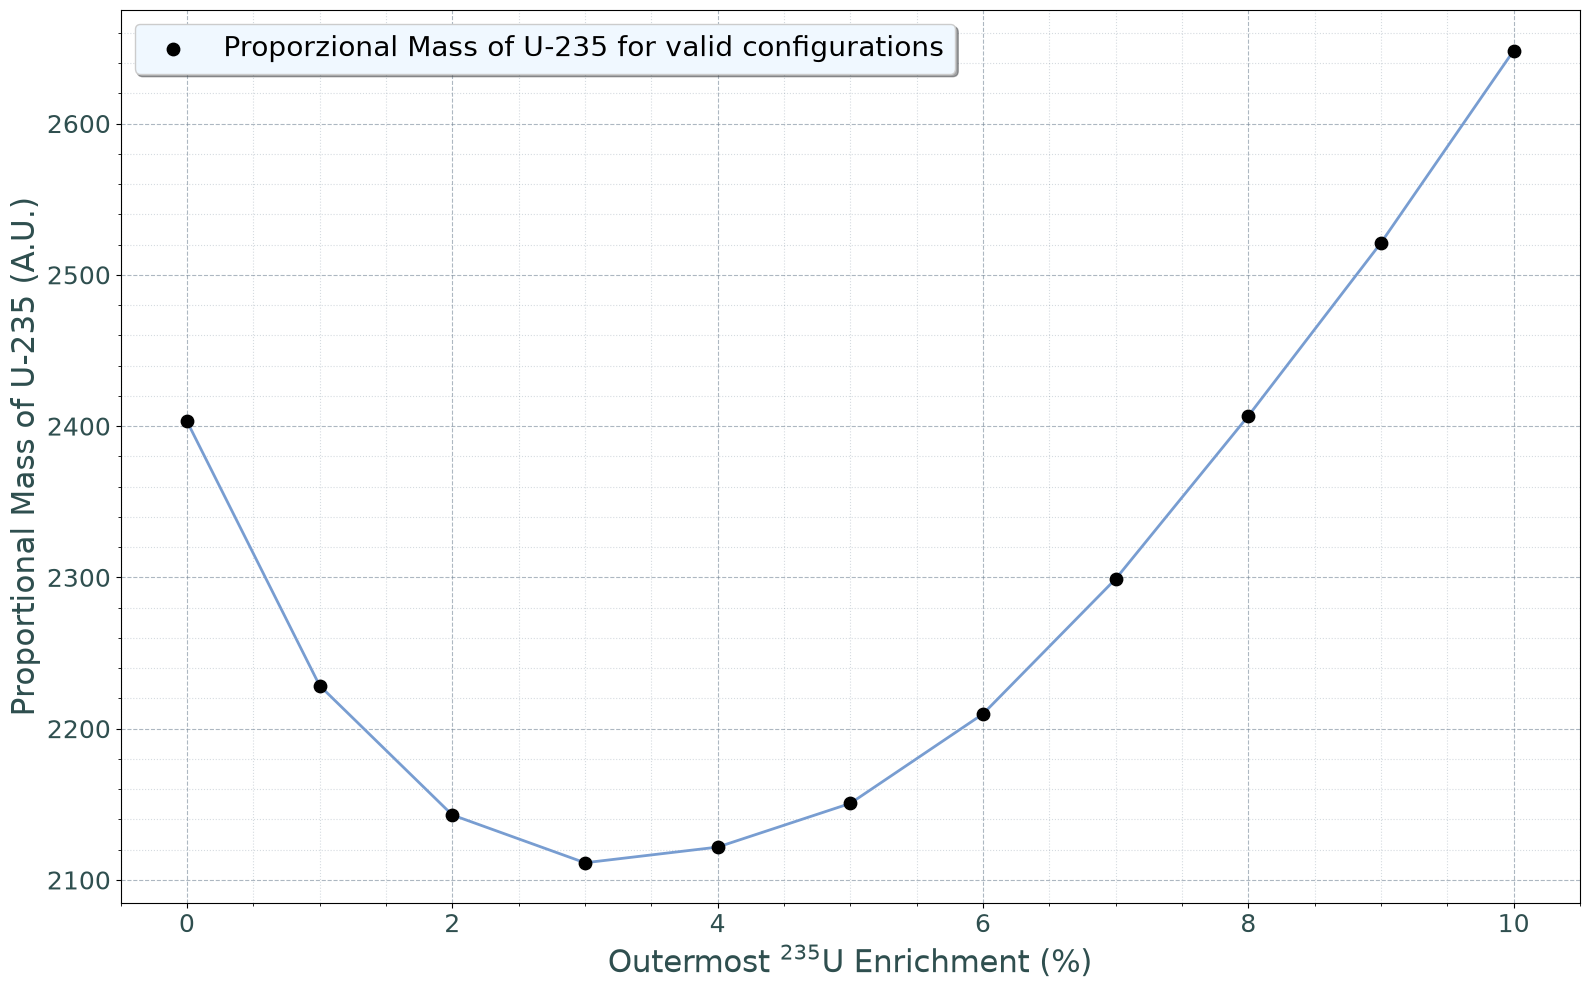

In [5]:
def calcola_e_plotta_massa(x_pred, y_pred):

    print("\n### --- Analisi Massa Proporzionale U-235 --- ###\n")
    
    # Definizione geometria anelli
    anelli = np.arange(2, 12)
    print(f"Anelli considerati (incluso 0 centrale): {anelli}")
    n_barre = 6 * (anelli)
    
    valid_x = []
    mass_vect = []
    
    for i, (x_p, y_p) in enumerate(zip(x_pred, y_pred)):
        y_start = y_p
        y_end = x_p
        
        # Filtro: escludiamo le configurazioni con arricchimento iniziale nullo/negativo
        if y_start <= 0:
            continue
            
        # Calcolo coefficienti retta: e_n = m * n + q
        m = (y_end - y_start) / 10.0
        q = y_start - m * 1.0
        
        # Arricchimenti valutati sui punti discreti 1-11
        arricchimenti = m * anelli + q
        
        # Integrale discreto della massa: Somma(N_barre * arricchimento_n)
        massa_prop = np.sum(n_barre * arricchimenti)
        
        valid_x.append(x_p)
        mass_vect.append(massa_prop)
        print(f"Configurazione EXT={x_p:2.1f}, INT={y_start:5.2f} -> Massa Proporzionale: {massa_prop:.2f}")

    # Plot
    fig, ax = plt.subplots(figsize=(16, 10))
    
    # Linea di tendenza (Interpolazione)
    ax.plot(valid_x, mass_vect, color='#789DD1', linestyle='-', linewidth=2, zorder=4)
    
    # Punti sperimentali valutati
    ax.scatter(valid_x, mass_vect, color='#000000', s=80, zorder=5, label='Proporzional Mass of U-235 for valid configurations')
    
    # Formattazione assi e titolo
    ax.set_xlabel('Outermost $^{235}$U Enrichment (%)', fontsize=22,  color='#2F4F4F')
    ax.set_ylabel('Proportional Mass of U-235 (A.U.)', fontsize=22,  color='#2F4F4F')
    
    # Formattazione Tick (Major: 14, Minor: 12)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)
    
    # Setup della griglia avanzata
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Legenda (loc='best', fontsize=16)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')
    
    plt.tight_layout()
    #plt.savefig('deriva_massa_u235.png', dpi=300)
    plt.show()
    
    return np.array(valid_x), np.array(mass_vect)

# Chiamata della funzione usando i vettori elaborati dal tuo blocco precedente
x_val, massa_val = calcola_e_plotta_massa(x_pred, y_pred)

### --- Analisi Massa Proporzionale U-235 --- ###

Configurazione EXT=0.0%, INT=19.07% -> Massa Proporzionale U-235: 2622.54 (a.u.)
Configurazione EXT=1.0%, INT=15.59% -> Massa Proporzionale U-235: 2468.26 (a.u.)
Configurazione EXT=2.0%, INT=12.82% -> Massa Proporzionale U-235: 2411.34 (a.u.)
Configurazione EXT=3.0%, INT=10.47% -> Massa Proporzionale U-235: 2413.26 (a.u.)
Configurazione EXT=4.0%, INT= 8.46% -> Massa Proporzionale U-235: 2460.98 (a.u.)
Configurazione EXT=5.0%, INT= 6.59% -> Massa Proporzionale U-235: 2528.90 (a.u.)
Configurazione EXT=6.0%, INT= 4.97% -> Massa Proporzionale U-235: 2629.83 (a.u.)
Configurazione EXT=7.0%, INT= 3.58% -> Massa Proporzionale U-235: 2763.61 (a.u.)
Configurazione EXT=8.0%, INT= 2.34% -> Massa Proporzionale U-235: 2917.61 (a.u.)
Configurazione EXT=9.0%, INT= 1.15% -> Massa Proporzionale U-235: 3078.90 (a.u.)
Configurazione EXT=10.0%, INT= 0.07% -> Massa Proporzionale U-235: 3253.94 (a.u.)


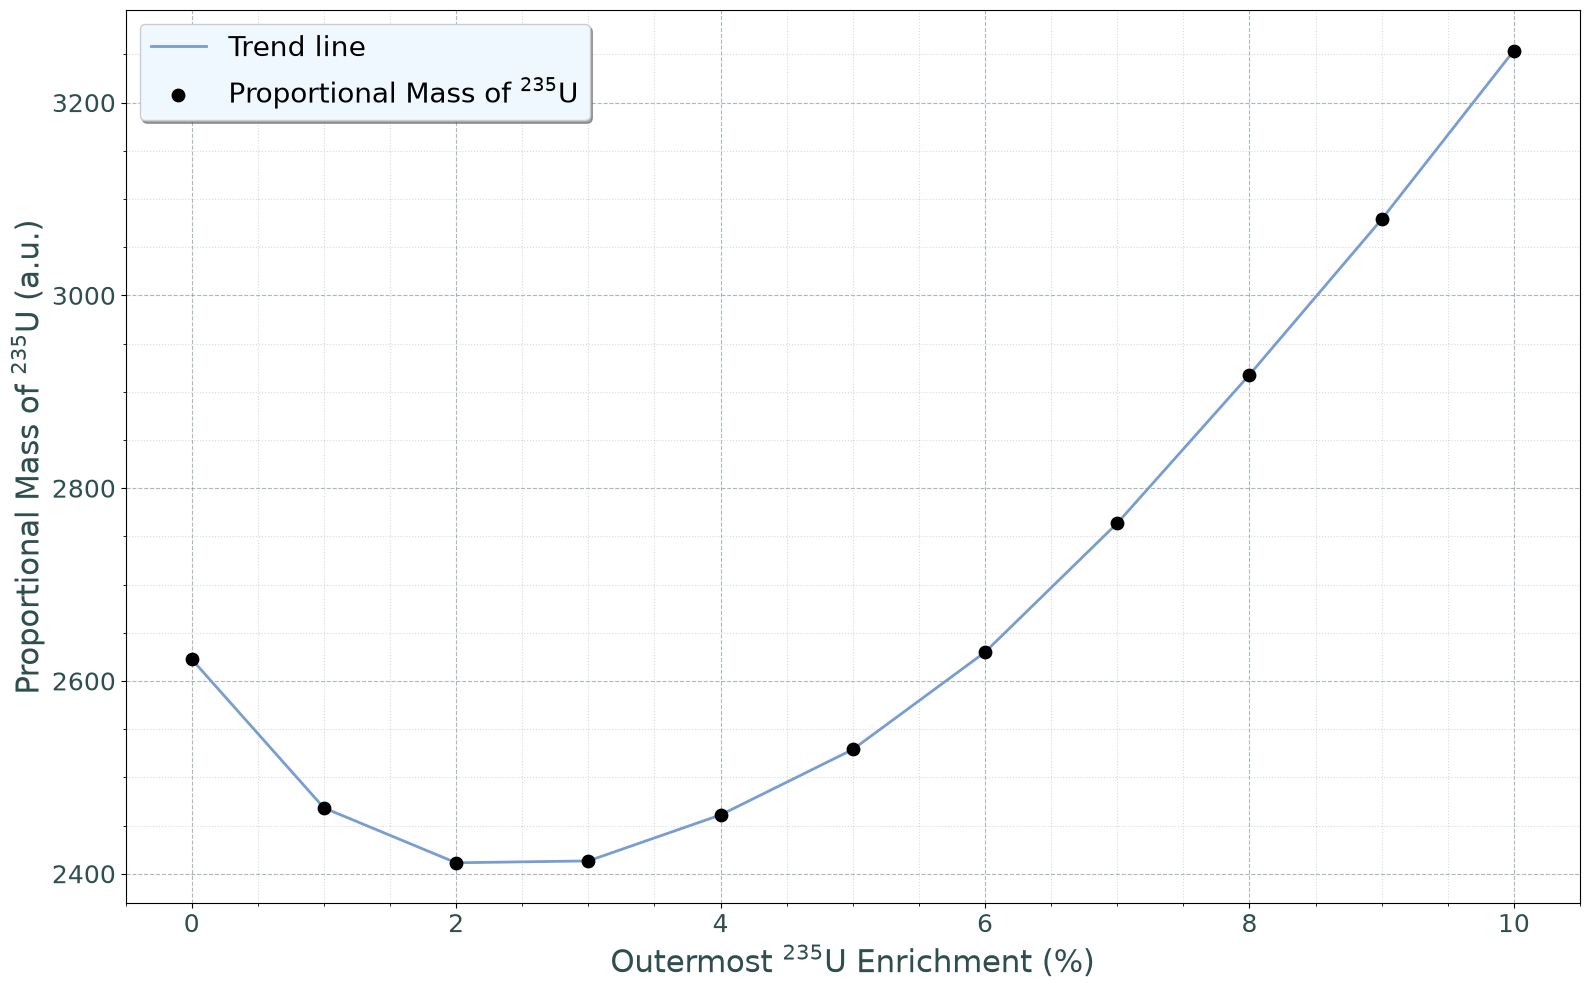

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def calcola_e_plotta_massa(x_pred, y_pred, num_rings=13, n_rings_removed=2):
    """
    Calcola e traccia la massa proporzionale di U-235 nel nocciolo in funzione
    dell'arricchimento esterno per le configurazioni subcritiche valide.
    
    num_rings: 13 (anelli totali 0..12)
    n_rings_removed: 2 (anelli 0 e 1 rimossi)
    """
    print("### --- Analisi Massa Proporzionale U-235 --- ###\n")
    
    # Anelli fisicamente presenti nel nocciolo (da 2 a 12 inclusi)
    anelli = np.arange(n_rings_removed, num_rings)
    n_barre = 6 * anelli  # Numero di barre di combustibile per anello n
    
    valid_x = []
    mass_vect = []
    
    for i, (x_p, y_p) in enumerate(zip(x_pred, y_pred)):
        y_start = y_p  # Arricchimento teorico al centro (anello 0)
        y_end = x_p    # Arricchimento all'anello esterno (anello 12)
        
        # Filtro: escludiamo le configurazioni con arricchimento iniziale nullo/negativo
        if y_start <= 0:
            continue
            
        # Pendenza del gradiente radiale: e_n = m * n + q
        m = (y_end - y_start) / (num_rings - 1)
        q = y_start
        
        # Arricchimenti valutati sugli anelli attivi (2-12)
        arricchimenti = m * anelli + q
        
        # Integrale discreto della massa: Somma(N_barre * arricchimento_n)
        massa_prop = np.sum(n_barre * arricchimenti)
        
        valid_x.append(x_p)
        mass_vect.append(massa_prop)
        print(f"Configurazione EXT={x_p:2.1f}%, INT={y_start:5.2f}% -> Massa Proporzionale U-235: {massa_prop:.2f} (a.u.)")

    # Creazione della Figura
    # Configurazione della Figura
    fig, ax = plt.subplots(figsize=(16, 10))
    
    # Linea di tendenza
    ax.plot(valid_x, mass_vect, color='#789DD1', linestyle='-', linewidth=2, zorder=4, label='Trend line')
    
    # Punti sperimentali
    ax.scatter(valid_x, mass_vect, color='#000000', s=80, zorder=5, label='Proportional Mass of $^{235}$U')
    
    # Formattazione Assi (Font 22, nessun grassetto, unità tra tonde)
    ax.set_xlabel('Outermost $^{235}$U Enrichment (%)', fontsize=22, color='#2F4F4F')
    ax.set_ylabel('Proportional Mass of $^{235}$U (a.u.)', fontsize=22, color='#2F4F4F')
    
    # Formattazione Tick
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)
    
    # Setup della griglia
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Setup Legenda (loc='best', fontsize=20)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')
    
    plt.tight_layout()
    plt.savefig('deriva_massa_u235.png', dpi=300)
    plt.show()
    
    return np.array(valid_x), np.array(mass_vect)

# Esecuzione del calcolo usando i vettori elaborati
x_val, massa_val = calcola_e_plotta_massa(x_pred, y_pred)

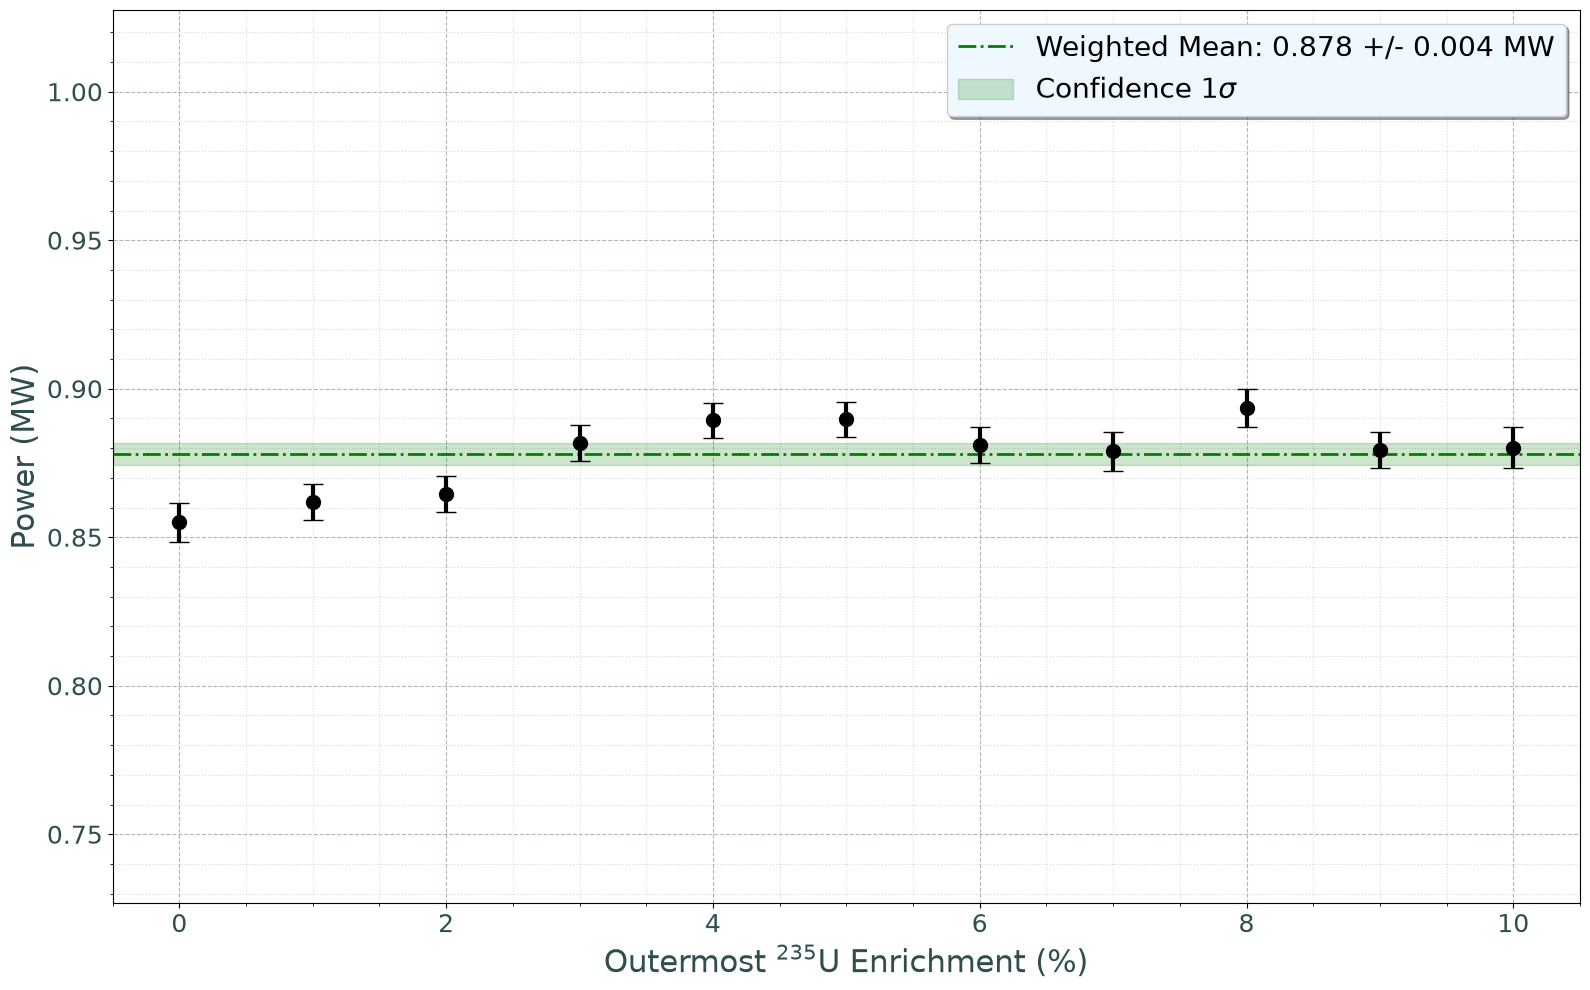

In [7]:
import glob
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
import openmc

# Costanti fisiche
E_FISSION_J = 200.0 * 1e6 * 1.6022e-19  # Energia media per fissione [J]
S_INTENSITY = 2.02e17                    # Fotoni/s dal sincrotrone

def parse_result_final(filename):
    """Parsa il file result_final.txt per ottenere i parametri di k."""
    data = []
    with open(filename, 'r') as file:
        for line in file:
            line = line.strip()
            if not line or line.startswith('-') or line.startswith('=') or 'Pres [Atm]' in line:
                continue
            cols = line.split()
            if len(cols) == 12:
                try:
                    data.append(list(map(float, cols)))
                except ValueError:
                    continue
    columns = ['pressione_atm', 'moltiplicatore', 'perc_water', 'arricch_INT', 'arricch_EXT', 
               't_water', 't_fuel', 'k_max', 'std_k_max', 'k_auto', 'std_k_auto', 'compatibilita']
    return pd.DataFrame(data, columns=columns)

def analizza_potenza():
    """Estrae dati, applica correzione del bias k e propaga l'errore."""
    file_list = glob.glob("../fixed/statepoints/statepoint_arr_ext_*.h5")
    df_res = parse_result_final('../result_final.txt')
    
    if not file_list or df_res.empty:
        print("Dati mancanti (statepoints o result_final.txt).")
        return pd.DataFrame()
        
    dati = []
    pattern = re.compile(r"statepoint_arr_ext_(\d+)_pitch_([\d\.]+)\.h5")

    for file_sp in file_list:
        filename = os.path.basename(file_sp)
        match = pattern.search(filename)
        if not match:
            continue
            
        molt = float(match.group(2))
        arr_ext = float(match.group(1)) 
        
        # Matching con result_final.txt (uso isclose per precisione float)
        row = df_res[(np.isclose(df_res['arricch_EXT'], arr_ext)) & 
                     (np.isclose(df_res['moltiplicatore'], molt))]
        
        if row.empty:
            continue
            
        k_sim = row['k_auto'].values[0]
        k_ref = row['k_max'].values[0]
        sigma_k_sim = row['std_k_auto'].values[0]

        with openmc.StatePoint(file_sp) as sp:
            try:
                tally = sp.get_tally(name='fission_tot')
                fission_mean = tally.mean.flatten()[0]
                fission_std = tally.std_dev.flatten()[0]
            except KeyError:
                continue
                
        # Calcolo Potenza simulata [MW]
        p_sim = (fission_mean * S_INTENSITY * E_FISSION_J) / 1e6
        err_sim = (fission_std * S_INTENSITY * E_FISSION_J) / 1e6
        
        # --- Correzione Bias k ---
        # dP/dk = P / (1-k)
        sensitivita = p_sim / (k_sim * (1 - k_sim))
        
        # Traslazione al valore di riferimento k_max
        p_corr = p_sim + sensitivita * (k_ref - k_sim)
        
        # Propagazione errore stocastico tally + incertezza statistica su k
        err_corr = np.sqrt(err_sim**2 + (sensitivita**2) * (sigma_k_sim**2))
        
        dati.append({
            'Arricchimento': arr_ext,
            'Moltiplicatore': molt,
            'Potenza_MW': p_corr,
            'Errore_MW': err_corr
        })
        
    return pd.DataFrame(dati)

def plot_scatter_smooth_err(df):
    """Visualizzazione con stile unificato e correzione bias."""
    if df.empty:
        return
        
    fig, ax = plt.subplots(figsize=(16, 10))
    moltiplicatori = df['Moltiplicatore'].unique()
    
    for m in moltiplicatori:
        df_m = df[df['Moltiplicatore'] == m].sort_values(by='Arricchimento')
        x = df_m['Arricchimento'].values
        y = df_m['Potenza_MW'].values
        y_err = df_m['Errore_MW'].values
        
        ax.errorbar(x, y, yerr=y_err, fmt='o', color='#000000', ecolor="#000000", 
                    elinewidth=3, capsize=7, zorder=5, markersize=10)
        
        #if len(x) >= 3:
        #    x_smooth = np.linspace(x.min(), x.max(), 300)
        #    spline = make_interp_spline(x, y, k=3)
        #    y_smooth = spline(x_smooth)
        #    ax.plot(x_smooth, y_smooth, zorder=4, label=f'Spline')
        #else:
        #    ax.plot(x, y, zorder=4)

    # Analisi statistica globale
    pesi = 1.0 / (df['Errore_MW']**2)
    media_pesata = np.sum(df['Potenza_MW'] * pesi) / np.sum(pesi)
    errore_media = 1.0 / np.sqrt(np.sum(pesi))
    chi_quadro = np.sum(((df['Potenza_MW'] - media_pesata)**2) / (df['Errore_MW']**2))
    chi_ridotto = chi_quadro / (len(df) - 1)

    errore_media = errore_media * np.sqrt(max(1, chi_ridotto))
    
    ax.axhline(y=media_pesata, color='green', linestyle='-.', linewidth=2, 
               zorder=3, label=f'Weighted Mean: {media_pesata:.3f} +/- {errore_media:.3f} MW')
    ax.axhspan(ymin=media_pesata - errore_media, ymax=media_pesata + errore_media, 
               color='green', alpha=0.2, zorder=2, label=r'Confidence $1\sigma$')
            
# Formattazione
    ax.set_xlabel('Outermost $^{235}$U Enrichment (%)', fontsize=22, color='#2F4F4F')
    ax.set_ylabel('Power (MW)', fontsize=22, color='#2F4F4F')
    
    # Formattazione Tick (Major: 14, Minor: 12)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)
    
    # Griglia avanzata
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Legenda (loc='best', fontsize=16)
    ax.legend(loc='best', frameon=True, shadow=True, 
              fontsize=20, facecolor='#F0F8FF')

    plt.ylim(df['Potenza_MW'].min() * 0.85, df['Potenza_MW'].max() * 1.15)
    
    plt.tight_layout()
    plt.savefig('scatter_potenza_errore.png', dpi=300)
    plt.show()

# Esecuzione
df_potenza = analizza_potenza()
plot_scatter_smooth_err(df_potenza)

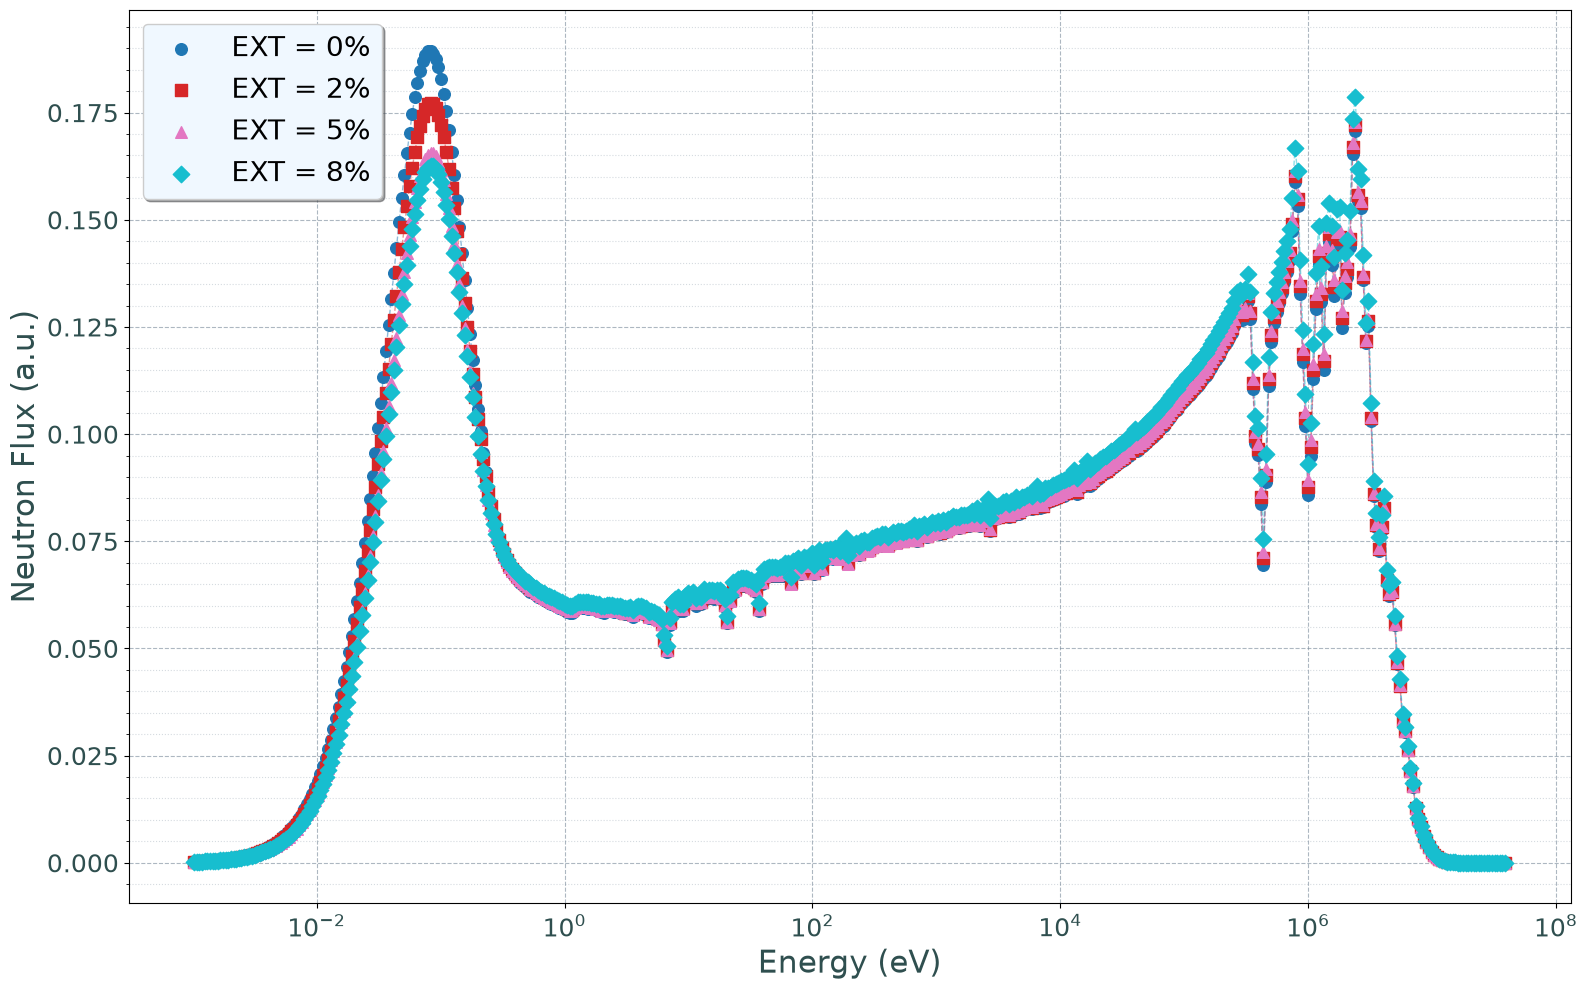

In [13]:
import glob
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import openmc

def plot_spettri_selezionati(arr_selezionati):
    """
    Traccia gli spettri neutronici energetici a punti discreti (scatter)
    per una selezione di arricchimenti esterni, con marcatori e colori distinti.
    """
    file_list = glob.glob("../fixed/statepoints/statepoint_arr_ext_*.h5")

    if not file_list:
        print("Nessun file statepoint trovato.")
        return

    # Regex robusta per decimali/interi
    pattern = re.compile(r"statepoint_arr_ext_([\d\.]+)_pitch_([\d\.]+)\.h5")

    # Configurazione della Figura (16, 10)
    fig, ax = plt.subplots(figsize=(16, 10))

    # Marcatori geometrici e Palette Colori
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    colors = cm.tab10(np.linspace(0, 1, len(arr_selezionati)))

    idx_style = 0

    for file_sp in sorted(file_list):
        filename = os.path.basename(file_sp)
        match = pattern.search(filename)

        if not match:
            continue

        arr_val = float(match.group(1))

        # Filtro: processiamo solo gli arricchimenti presenti nella lista desiderata
        if not any(np.isclose(arr_val, target) for target in arr_selezionati):
            continue

        with openmc.StatePoint(file_sp) as sp:
            try:
                # Estrazione tally dello spettro
                tally = sp.tallies[5]
                df = tally.get_pandas_dataframe()
            except (KeyError, AttributeError):
                continue

            neutrons = df[df['particle'] == 'neutron']

            E_low = neutrons['energy low [eV]'].values
            E_high = neutrons['energy high [eV]'].values

            # Media geometrica del bin energetico
            E_mid = np.sqrt(E_low * E_high)
            flux = neutrons['mean'].values

            marker = markers[idx_style % len(markers)]
            color = colors[idx_style % len(colors)]

            # Scatter plot per evidenziare la discretizzazione
            ax.scatter(
                E_mid, 
                flux, 
                color=color, 
                marker=marker, 
                s=70, 
                zorder=5, 
                label=f'EXT = {arr_val:.0f}%'
            )
            
            # Tratto leggero di congiunzione per seguire il profilo dello spettro
            ax.plot(
                E_mid, 
                flux, 
                color=color, 
                linestyle='--', 
                linewidth=1, 
                alpha=0.5, 
                zorder=4
            )

            idx_style += 1

    # Scala logaritmica sull'asse dell'energia
    ax.set_xscale('log')

    # Formattazione Assi (Font 22, nessun grassetto, unità tra tonde)
    ax.set_xlabel('Energy (eV)', fontsize=22, color='#2F4F4F')
    ax.set_ylabel('Neutron Flux (a.u.)', fontsize=22, color='#2F4F4F')

    # Formattazione Tick
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)

    # Setup della griglia avanzata
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')

    # Setup Legenda (loc='best', fontsize=20)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')

    plt.tight_layout()
    plt.savefig('spettro_neutronico_discreto.png', dpi=300)
    plt.show()

# Esecuzione per la selezione desiderata (es. 0%, 2%, 5%, 8%, 10%)
plot_spettri_selezionati(arr_selezionati=[0, 2, 5, 8])

Il Peaking Factor (o fattore di picco) è un parametro adimensionale fondamentale nella fisica e nell'ingegneria dei reattori nucleari che misura la disomogeneità spaziale della distribuzione di potenza o di flusso neutronico all'interno del nocciolo12.In termini generali, definisce quanto il valore locale massimo di potenza si discosta dal valore medio dell'intero reattore:$$\text{Peaking Factor} = \frac{\text{Potenza Massima Locale (o di canale)}}{\text{Potenza Media del Nocciolo}}$$1. Perché è così importante per la sicurezza e la progettazione?In un reattore nucleare, la potenza termica totale prodotta (ad esempio $0.88\text{ MW}_{\text{th}}$ o $1500\text{ MW}_{\text{th}}$) è limitata dal punto più caldo del sistema (hot-spot)23.Limiti termoidraulici: Se in un voxel o in una fetta di combustibile la potenza prodotta per unità di volume ($\text{W/cm}^3$) o di lunghezza ($\text{W/cm}$) supera le soglie di tolleranza, la guaina (cladding) o le pastiglie di combustibile rischiano lo stress termico o la fusione3.Efficienza (Power Flattening): Più il Peaking Factor è vicino a $1$, più la potenza è "piatta" e uniforme34. Questo permette di estrarre più energia globale senza mai superare i vincoli di sicurezza locali3.2. I principali Peaking FactorsA seconda della direzione spaziale e della risoluzione considerata, si distinguono tre fattori di picco principali:A. $F_r$ — Peaking Factor RadialeMisura lo sbilanciamento della potenza sul piano trasversale $(x,y)$. $$F_r = \frac{\text{Potenza del canale/anello radiale più caldo}}{\text{Potenza radiale media}}$$ Nei reattori ADS (Accelerator-Driven Systems) con sorgente esterna al centro, il flusso neutronico tende ad avere un picco elevatissimo nella regione centrale23. Per questo motivo si adotta la strategia di fuel zoning (arricchimento radiale variabile), abbassando l'arricchimento al centro e alzandolo in periferia per appiattire la potenza radiale e ridurre $F_r$34.B. $F_z$ — Peaking Factor AssialeMisura lo sbilanciamento lungo l'altezza del nocciolo (asse $z$). $$F_z = \frac{\text{Potenza lineare massima } q' [\text{W/cm}]}{\text{Potenza lineare media } q' [\text{W/cm}]}$$ Solitamente segue il profilo di flusso assiale (spesso di forma cosinusoidale nei reattori omogenei, con picco sul piano medio $z = H/2$)5.C. $F_q$ — Peaking Factor Tridimensionale (Totale / Hot-Spot Factor)È il fattore di picco locale tridimensionale reale: $$F_q = \frac{\max P(x,y,z)}{\bar{P}_{\text{3D, core}}}$$ Confronta la potenza del singolo voxel 3D più caldo dell'intero nocciolo con la potenza media di tutti i voxel attivi. Se la distribuzione di potenza fosse perfettamente separabile nelle sue componenti radiale ed assiale ($P(x,y,z) = R(x,y) \cdot Z(z)$), si avrebbe $F_q \approx F_r \cdot F_z$. Nei reattori reali, $F_q$ tiene conto delle inclinazioni locali e delle deviazioni dalla separabilità ideale.

statepoint_arr_ext_0_pitch_1.h5 | Fr=2.663±0.036 | Fz=1.673±0.023 | Fq=4.906±0.066
statepoint_arr_ext_10_pitch_1.h5 | Fr=2.404±0.027 | Fz=1.423±0.016 | Fq=3.257±0.037
statepoint_arr_ext_1_pitch_1.h5 | Fr=2.605±0.027 | Fz=1.616±0.017 | Fq=4.583±0.048
statepoint_arr_ext_2_pitch_1.h5 | Fr=2.563±0.027 | Fz=1.571±0.017 | Fq=4.346±0.046
statepoint_arr_ext_3_pitch_1.h5 | Fr=2.525±0.027 | Fz=1.533±0.016 | Fq=4.094±0.043
statepoint_arr_ext_4_pitch_1.h5 | Fr=2.494±0.026 | Fz=1.502±0.016 | Fq=3.892±0.041
statepoint_arr_ext_5_pitch_1.h5 | Fr=2.469±0.027 | Fz=1.476±0.016 | Fq=3.718±0.040
statepoint_arr_ext_6_pitch_1.h5 | Fr=2.445±0.026 | Fz=1.457±0.016 | Fq=3.534±0.038
statepoint_arr_ext_7_pitch_1.h5 | Fr=2.431±0.027 | Fz=1.441±0.016 | Fq=3.370±0.037
statepoint_arr_ext_8_pitch_1.h5 | Fr=2.415±0.026 | Fz=1.432±0.016 | Fq=3.271±0.036
statepoint_arr_ext_9_pitch_1.h5 | Fr=2.412±0.026 | Fz=1.424±0.016 | Fq=3.247±0.036


,Arricchimento,Moltiplicatore,Fr,Fr_err,Fz,Fz_err,Fq,Fq_err,FrFz
0,0.0,1.0,2.663150,0.035932,1.673483,0.022579,4.906056,0.066194,4.456735
2,1.0,1.0,2.605120,0.027199,1.615835,0.016870,4.583383,0.047854,4.209445
3,2.0,1.0,2.563370,0.027147,1.571244,0.016640,4.346258,0.046028,4.027680
4,3.0,1.0,2.524766,0.026665,1.532643,0.016187,4.093904,0.043237,3.869565
5,4.0,1.0,2.493554,0.026404,1.502176,0.015906,3.891626,0.041207,3.745757
6,5.0,1.0,2.468839,0.026639,1.475995,0.015926,3.718494,0.040124,3.643994
7,6.0,1.0,2.444964,0.026470,1.456755,0.015771,3.534242,0.038263,3.561713
8,7.0,1.0,2.430619,0.026924,1.441127,0.015963,3.369955,0.037329,3.502829
9,8.0,1.0,2.415251,0.026242,1.431909,0.015558,3.271422,0.035544,3.458420
10,9.0,1.0,2.412340,0.026427,1.423904,0.015599,3.246678,0.035567,3.434941


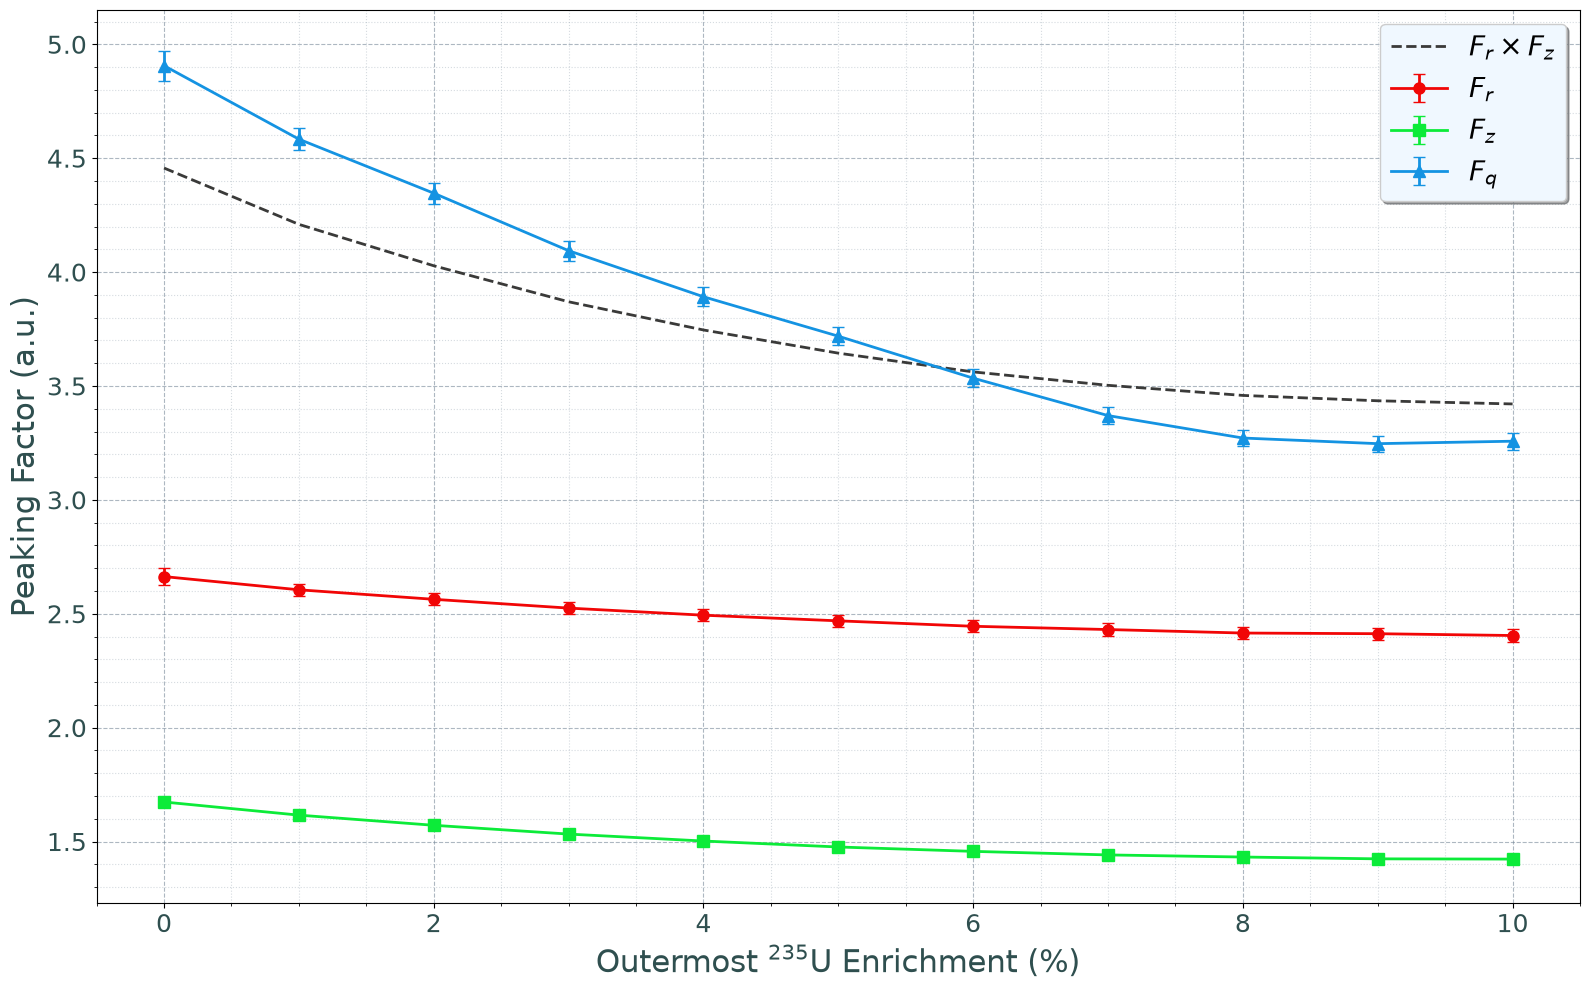

In [9]:
def analizza_peaking():

    file_list = glob.glob(
        "../fixed/statepoints/statepoint_arr_ext_*.h5"
    )

    pattern = re.compile(
        r"statepoint_arr_ext_(\d+)_pitch_([\d\.]+)\.h5"
    )

    dati = []

    for file_sp in sorted(file_list):

        filename = os.path.basename(file_sp)

        match = pattern.search(filename)

        if not match:
            continue

        arricchimento = float(match.group(1))
        moltiplicatore = float(match.group(2))

        try:

            with openmc.StatePoint(file_sp) as sp:

                tally = sp.get_tally(
                    name='tally_3d_power'
                )

                mean = tally.mean[:,0,1].flatten()
                std  = tally.std_dev[:,0,1].flatten()

                mesh = tally.filters[0].mesh

                nx, ny, nz = mesh.dimension

                mean = mean.reshape(
                    (nx, ny, nz)
                )

                std = std.reshape(
                    (nx, ny, nz)
                )

                # ------------------------------
                # Calcolo errore relativo medio
                # ------------------------------

                mask = mean > 0

                if np.sum(mask) == 0:
                    print(
                        f"{filename}: tutti valori nulli"
                    )
                    continue

                rel_err = np.mean(
                    std[mask] / mean[mask]
                )

                # ------------------------------
                # Fq
                # ------------------------------

                Fq = (
                    mean.max()
                    /
                    mean.mean()
                )

                err_Fq = Fq * rel_err

                # ------------------------------
                # Fr
                # ------------------------------

                power_xy = mean.sum(axis=2)

                Fr = (
                    power_xy.max()
                    /
                    power_xy.mean()
                )

                err_Fr = Fr * rel_err

                # ------------------------------
                # Fz
                # ------------------------------

                power_z = mean.sum(
                    axis=(0, 1)
                )

                Fz = (
                    power_z.max()
                    /
                    power_z.mean()
                )

                err_Fz = Fz * rel_err

                dati.append({

                    "Arricchimento":
                    arricchimento,

                    "Moltiplicatore":
                    moltiplicatore,

                    "Fr":
                    Fr,

                    "Fr_err":
                    err_Fr,

                    "Fz":
                    Fz,

                    "Fz_err":
                    err_Fz,

                    "Fq":
                    Fq,

                    "Fq_err":
                    err_Fq,

                    "FrFz":
                    Fr * Fz

                })

                print(
                    f"{filename} | "
                    f"Fr={Fr:.3f}±{err_Fr:.3f} | "
                    f"Fz={Fz:.3f}±{err_Fz:.3f} | "
                    f"Fq={Fq:.3f}±{err_Fq:.3f}"
                )

        except Exception as e:

            print(
                f"Errore in {filename}"
            )

            print(e)

    return pd.DataFrame(dati)


# =====================================================
# ELABORAZIONE
# =====================================================

df_peak = analizza_peaking()

df_peak = df_peak.sort_values(
    "Arricchimento"
)

display(df_peak)


# =====================================================
# PLOT
# =====================================================

# Configurazione della Figura (16, 10)
fig, ax = plt.subplots(figsize=(16, 10))

# Plot Fr
ax.errorbar(
    df_peak["Arricchimento"],
    df_peak["Fr"],
    yerr=df_peak["Fr_err"],
    fmt='o-',
    color="#F10606",
    ecolor='#F10606',
    capsize=4,
    elinewidth=2,
    linewidth=2,
    markersize=8,
    zorder=5,
    label=r"$F_r$"
)

# Plot Fz
ax.errorbar(
    df_peak["Arricchimento"],
    df_peak["Fz"],
    yerr=df_peak["Fz_err"],
    fmt='s-',
    color="#0CEB39",
    ecolor='#0CEB39',
    capsize=4,
    elinewidth=2,
    linewidth=2,
    markersize=8,
    zorder=5,
    label=r"$F_z$"
)

# Plot Fq
ax.errorbar(
    df_peak["Arricchimento"],
    df_peak["Fq"],
    yerr=df_peak["Fq_err"],
    fmt='^-',
    color="#1493E2",
    ecolor='#1493E2',
    capsize=4,
    elinewidth=2,
    linewidth=2,
    markersize=8,
    zorder=5,
    label=r"$F_q$"
)

# Plot Fr x Fz
ax.plot(
    df_peak["Arricchimento"],
    df_peak["FrFz"],
    '--',
    color="#3A3A39",
    linewidth=2,
    zorder=4,
    label=r"$F_r \times F_z$"
)

# Formattazione Assi (Font 22, nessun grassetto, unità tra tonde)
ax.set_xlabel("Outermost $^{235}$U Enrichment (%)", fontsize=22, color='#2F4F4F')
ax.set_ylabel("Peaking Factor (a.u.)", fontsize=22, color='#2F4F4F')

# Formattazione Tick
ax.minorticks_on()
ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
ax.tick_params(axis='both', which='minor', labelsize=12)

# Setup della griglia avanzata
ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')

# Setup Legenda (loc='best', fontsize=20)
ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')

plt.tight_layout()
plt.savefig('peaking_factors.png', dpi=300)
plt.show()

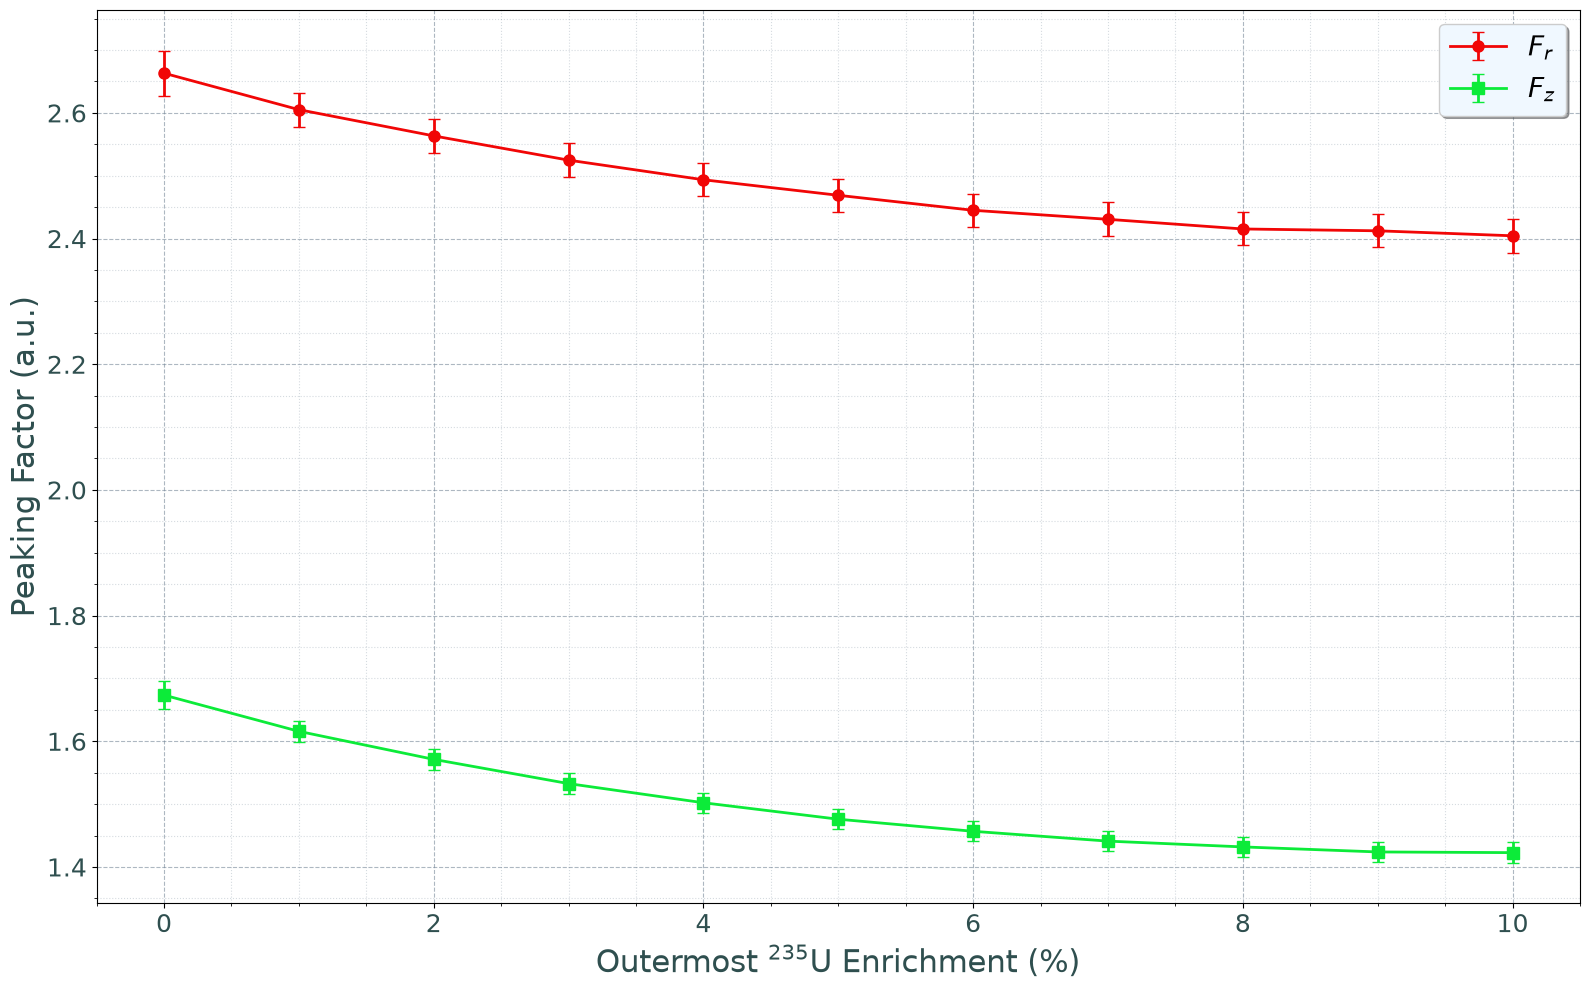

In [10]:
fig, ax = plt.subplots(figsize=(16, 10))

# Plot Fr
ax.errorbar(
    df_peak["Arricchimento"],
    df_peak["Fr"],
    yerr=df_peak["Fr_err"],
    fmt='o-',
    color="#F10606",
    ecolor='#F10606',
    capsize=4,
    elinewidth=2,
    linewidth=2,
    markersize=8,
    zorder=5,
    label=r"$F_r$"
)

# Plot Fz
ax.errorbar(
    df_peak["Arricchimento"],
    df_peak["Fz"],
    yerr=df_peak["Fz_err"],
    fmt='s-',
    color="#0CEB39",
    ecolor='#0CEB39',
    capsize=4,
    elinewidth=2,
    linewidth=2,
    markersize=8,
    zorder=5,
    label=r"$F_z$"
)


# Formattazione Assi (Font 22, nessun grassetto, unità tra tonde)
ax.set_xlabel("Outermost $^{235}$U Enrichment (%)", fontsize=22, color='#2F4F4F')
ax.set_ylabel("Peaking Factor (a.u.)", fontsize=22, color='#2F4F4F')

# Formattazione Tick
ax.minorticks_on()
ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
ax.tick_params(axis='both', which='minor', labelsize=12)

# Setup della griglia avanzata
ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')

# Setup Legenda (loc='best', fontsize=20)
ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')

plt.tight_layout()
plt.savefig('peaking_factors_zoom.png', dpi=300)
plt.show()